<a href="https://colab.research.google.com/github/PreethiR091/Deep-Learning/blob/main/Preethi_R_24BAD091_DL_Ex_no_7_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Preethi R 24BAD091

EXPT NO: 7 - IMPLEMENTATION OF A SIMPLE AUTOENCODER FOR DIMENSIONALITY REDUCTION AND FEATURE LEARNING

PART A: DATASET PREPARATION

Objective: Load the MNIST dataset, explore the images, normalize pixel values, reshape the images and split the dataset into training and testing sets.

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Student Name: Preethi R
Roll Number: 24BAD091
Training Data Shape: (60000, 28, 28)
Testing Data Shape: (10000, 28, 28)
Data Type: uint8


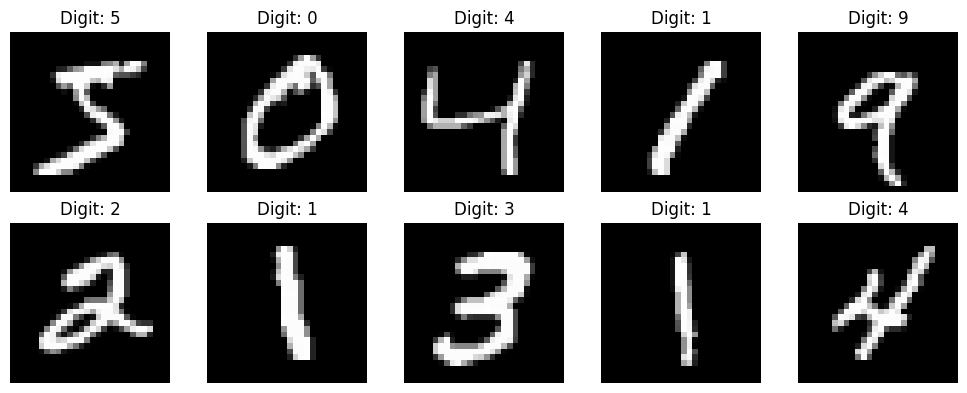

Training Input Shape: (54000, 784)
Validation Input Shape: (6000, 784)
Testing Input Shape: (10000, 784)
Normalized Minimum: 0.0
Normalized Maximum: 1.0


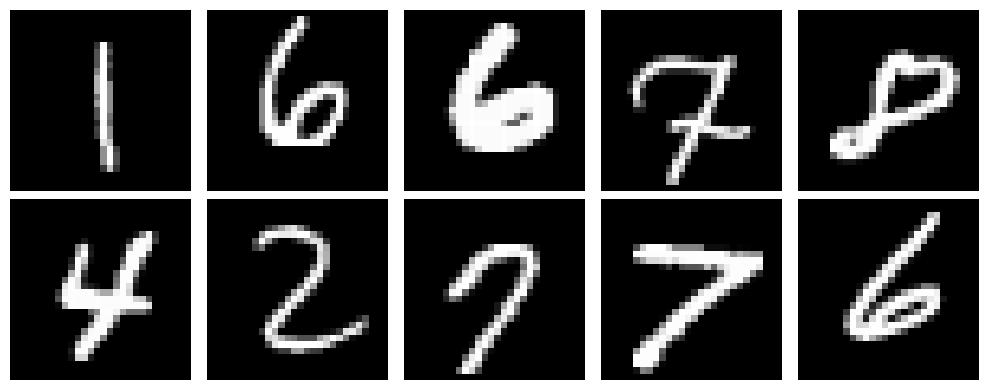

In [1]:
# Student Details
student_name = "Preethi R"
roll_no = "24BAD091"

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.datasets import mnist
from sklearn.model_selection import train_test_split

# Load MNIST dataset
(x_train, y_train), (x_test, y_test) = mnist.load_data()

# Display dataset information
print("Student Name:", student_name)
print("Roll Number:", roll_no)
print("Training Data Shape:", x_train.shape)
print("Testing Data Shape:", x_test.shape)
print("Data Type:", x_train.dtype)

# Display sample original images
plt.figure(figsize=(10, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(f"Digit: {y_train[i]}")
    plt.axis('off')

plt.tight_layout()
plt.show()

# Normalize pixel values between 0 and 1
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

# Reshape images into one-dimensional vectors
x_train = x_train.reshape(-1, 784)
x_test = x_test.reshape(-1, 784)

# Split training data into training and validation data
x_train, x_val = train_test_split(
    x_train, test_size=0.1, random_state=42
)

# Use input data as target output
print("Training Input Shape:", x_train.shape)
print("Validation Input Shape:", x_val.shape)
print("Testing Input Shape:", x_test.shape)
print("Normalized Minimum:", x_train.min())
print("Normalized Maximum:", x_train.max())

# Display original images
plt.figure(figsize=(10, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i].reshape(28, 28), cmap='gray')
    plt.axis('off')

plt.tight_layout()
plt.show()

PART B: IMPLEMENTING THE AUTOENCODER MODEL

Objective: Build an Autoencoder using Encoder, Bottleneck and Decoder layers. Compile the model and display its architecture.

Student Name: Preethi R
Roll Number: 24BAD091

ENCODER SUMMARY


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         4,128 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 104,608 (408.62 KB)

 Trainable params: 104,608 (408.62 KB)

 Non-trainable params: 0 (0.00 B)

... (8 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ functional (Functional)         │ (None, 32)             │       104,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ functional_1 (Functional)       │ (None, 784)            │       105,360 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 209,968 (820.19 KB)

 Trainable params: 209,968 (820.19 KB)

 Non-trainable params: 0 (0.00 B)

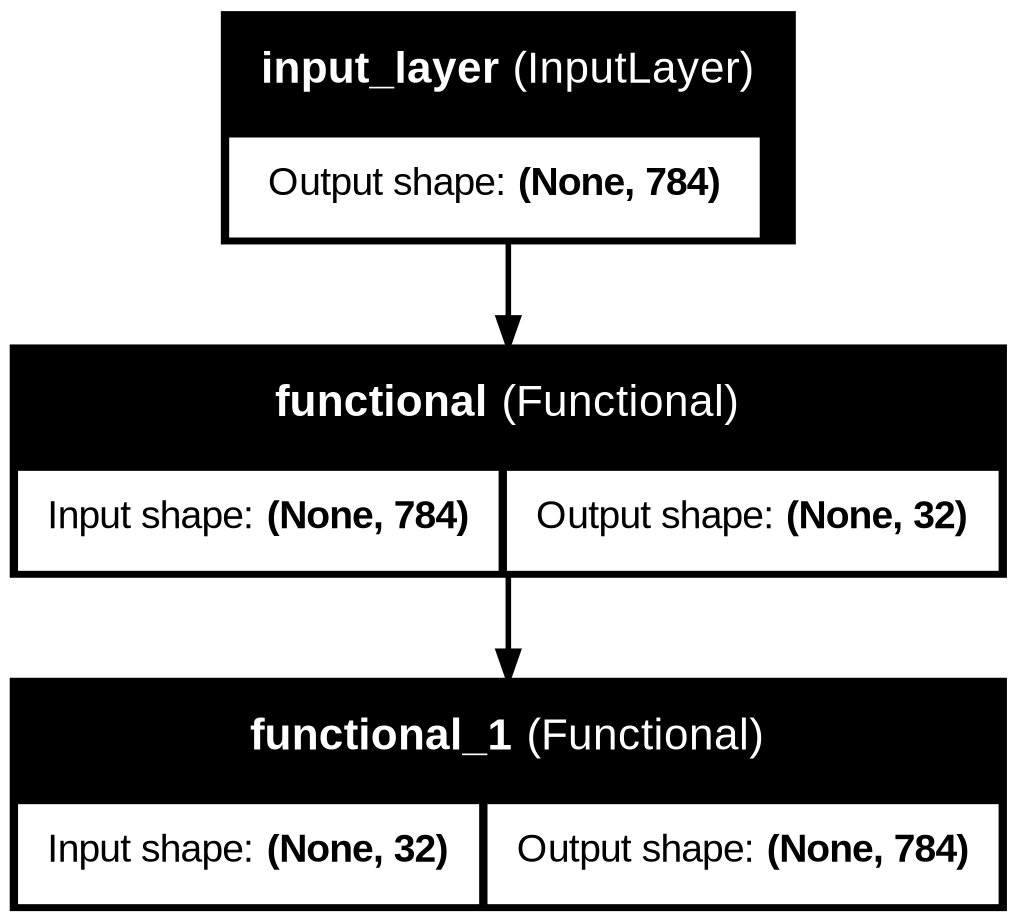

In [2]:
# Define input dimension and bottleneck dimension
input_dim = 784
encoding_dim = 32

# Define Encoder
input_layer = tf.keras.Input(shape=(input_dim,))

encoder_layer = tf.keras.layers.Dense(
    128, activation='relu'
)(input_layer)

bottleneck = tf.keras.layers.Dense(
    encoding_dim, activation='relu'
)(encoder_layer)

# Create Encoder model
encoder = tf.keras.Model(input_layer, bottleneck)

# Define Decoder
decoder_input = tf.keras.Input(shape=(encoding_dim,))

decoder_layer = tf.keras.layers.Dense(
    128, activation='relu'
)(decoder_input)

output_layer = tf.keras.layers.Dense(
    input_dim, activation='sigmoid'
)(decoder_layer)

# Create Decoder model
decoder = tf.keras.Model(decoder_input, output_layer)

# Combine Encoder and Decoder
autoencoder_output = decoder(encoder(input_layer))

autoencoder = tf.keras.Model(
    input_layer, autoencoder_output
)

# Compile Autoencoder
autoencoder.compile(
    optimizer='adam',
    loss='mse'
)

# Display model summary
print("Student Name: Preethi R")
print("Roll Number: 24BAD091")

print("\nENCODER SUMMARY")
encoder.summary()

print("\nDECODER SUMMARY")
decoder.summary()

print("\nAUTOENCODER SUMMARY")
autoencoder.summary()

# Display architecture
tf.keras.utils.plot_model(
    autoencoder,
    show_shapes=True,
    show_layer_names=True
)

PART C: MODEL TRAINING AND PERFORMANCE EVALUATION

Objective: Train the Autoencoder, record training and validation losses, calculate reconstruction MSE and compare original images with reconstructed images.

Epoch 1/20
211/211 ━━━━━━━━━━━━━━━━━━━━ 10s 36ms/step - loss: 0.0617 - val_loss: 0.0344
Epoch 2/20
211/211 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 0.0268 - val_loss: 0.0215
Epoch 3/20
211/211 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - loss: 0.0193 - val_loss: 0.0175
Epoch 4/20
211/211 ━━━━━━━━━━━━━━━━━━━━ 6s 19ms/step - loss: 0.0163 - val_loss: 0.0154
Epoch 5/20
211/211 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - loss: 0.0145 - val_loss: 0.0140
Epoch 6/20
211/211 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - loss: 0.0134 - val_loss: 0.0130
Epoch 7/20
211/211 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - loss: 0.0127 - val_loss: 0.0124
Epoch 8/20
211/211 ━━━━━━━━━━━━━━━━━━━━ 5s 22ms/step - loss: 0.0121 - val_loss: 0.0119
Epoch 9/20
211/211 ━━━━━━━━━━━━━━━━━━━━ 6s 29ms/step - loss: 0.0116 - val_loss: 0.0115
Epoch 10/20
211/211 ━━━━━━━━━━━━━━━━━━━━ 9s 41ms/step - loss: 0.0113 - val_loss: 0.0113
Epoch 11/20
211/211 ━━━━━━━━━━━━━━━━━━━━ 5s 23ms/step - loss: 0.0110 - val_loss: 0.0110
Epoch 12/20
211/211 ━━━━━━━━━━━━━━━━━━━━

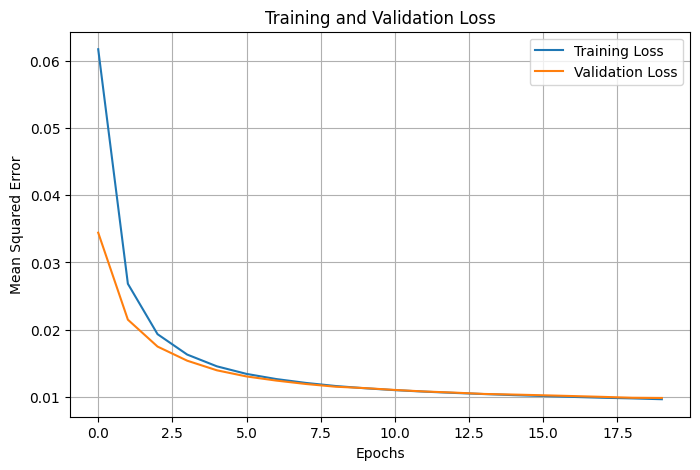

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step


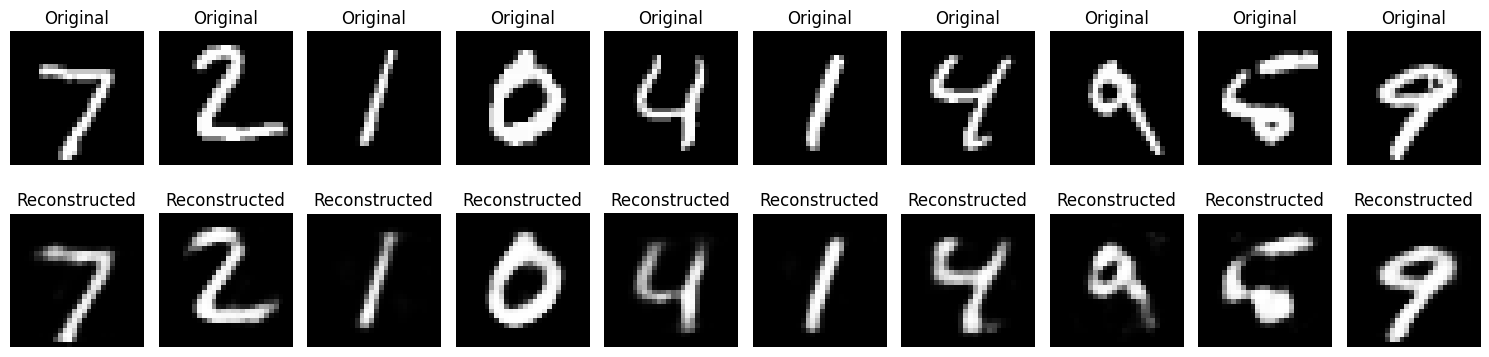

In [3]:
# Train the Autoencoder
history = autoencoder.fit(
    x_train,
    x_train,
    epochs=20,
    batch_size=256,
    shuffle=True,
    validation_data=(x_val, x_val)
)

# Evaluate model on test data
test_loss = autoencoder.evaluate(
    x_test, x_test, verbose=0
)

print("Student Name: Preethi R")
print("Roll Number: 24BAD091")
print("Test Reconstruction MSE:", test_loss)

# Display training and validation loss
plt.figure(figsize=(8, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.xlabel('Epochs')
plt.ylabel('Mean Squared Error')
plt.title('Training and Validation Loss')
plt.legend()
plt.grid()
plt.show()

# Reconstruct test images
reconstructed = autoencoder.predict(x_test[:10])

# Compare original and reconstructed images
plt.figure(figsize=(15, 4))

for i in range(10):
    plt.subplot(2, 10, i + 1)
    plt.imshow(x_test[i].reshape(28, 28), cmap='gray')
    plt.title("Original")
    plt.axis('off')

    plt.subplot(2, 10, i + 11)
    plt.imshow(reconstructed[i].reshape(28, 28), cmap='gray')
    plt.title("Reconstructed")
    plt.axis('off')

plt.tight_layout()
plt.show()

PART D: DIMENSIONALITY REDUCTION, FEATURE VISUALIZATION AND EXPERIMENT MANAGEMENT

Objective: Extract compressed features using the trained Encoder, compare dimensions, visualize latent representations and reconstruct selected images using the Decoder.

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
Student Name: Preethi R
Roll Number: 24BAD091
Original Data Shape: (1000, 784)
Compressed Data Shape: (1000, 32)


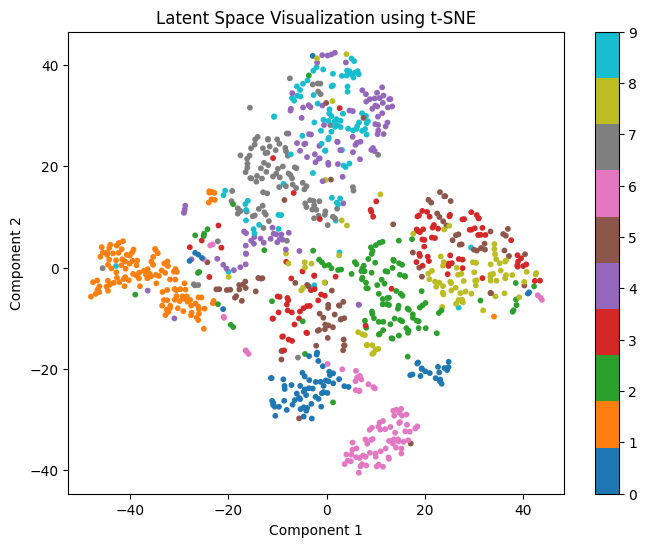

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step


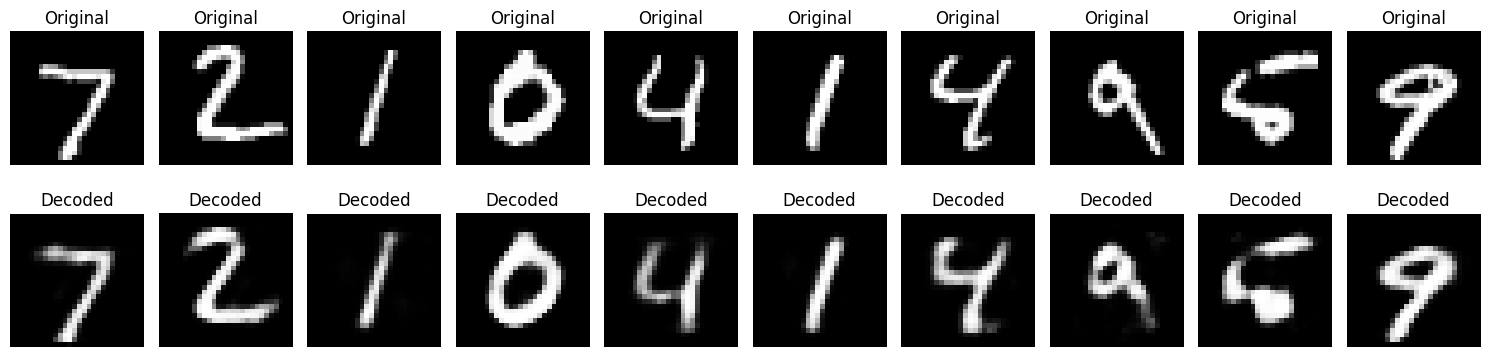

Original Dimensions: 784
Compressed Dimensions: 32
Dimensionality Reduction: 95.92 %
Models saved successfully.


In [4]:
from sklearn.manifold import TSNE

# Extract latent representations
latent_features = encoder.predict(x_test[:1000])

# Compare original and compressed dimensions
print("Student Name: Preethi R")
print("Roll Number: 24BAD091")

print("Original Data Shape:", x_test[:1000].shape)
print("Compressed Data Shape:", latent_features.shape)

# Visualize latent representations using t-SNE
tsne = TSNE(
    n_components=2,
    random_state=42,
    perplexity=30
)

latent_2d = tsne.fit_transform(latent_features)

plt.figure(figsize=(8, 6))

scatter = plt.scatter(
    latent_2d[:, 0],
    latent_2d[:, 1],
    c=y_test[:1000],
    cmap='tab10',
    s=10
)

plt.colorbar(scatter)
plt.title('Latent Space Visualization using t-SNE')
plt.xlabel('Component 1')
plt.ylabel('Component 2')
plt.show()

# Reconstruct selected test samples using Decoder
selected_features = latent_features[:10]
decoded_images = decoder.predict(selected_features)

# Compare original and reconstructed images
plt.figure(figsize=(15, 4))

for i in range(10):
    plt.subplot(2, 10, i + 1)
    plt.imshow(x_test[i].reshape(28, 28), cmap='gray')
    plt.title("Original")
    plt.axis('off')

    plt.subplot(2, 10, i + 11)
    plt.imshow(decoded_images[i].reshape(28, 28), cmap='gray')
    plt.title("Decoded")
    plt.axis('off')

plt.tight_layout()
plt.show()

# Calculate dimensionality reduction
original_features = 784
compressed_features = 32

reduction = (
    (original_features - compressed_features)
    / original_features
) * 100

print("Original Dimensions:", original_features)
print("Compressed Dimensions:", compressed_features)
print("Dimensionality Reduction:", round(reduction, 2), "%")

# Save trained models
encoder.save("encoder.keras")
decoder.save("decoder.keras")
autoencoder.save("autoencoder.keras")

print("Models saved successfully.")